In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("reservation_data_sample.csv", parse_dates=["NIGHT_OF_STAY", "DATE_OF_RESERVATION", "CANCELLATION_DATE"])

# Define target dates
TARGET_DATES = {
    "2022": pd.Timestamp("2022-07-16"),
    "2021": pd.Timestamp("2021-07-16")
}

def preprocess_data(df):
    """ Ensure correct date formats and remove unnecessary columns if needed. """
    date_cols = ["NIGHT_OF_STAY", "DATE_OF_RESERVATION", "CANCELLATION_DATE"]
    for col in date_cols:
        df[col] = pd.to_datetime(df[col], errors="coerce")
    return df

# Preprocess data
df = preprocess_data(df)

In [10]:

def compute_booking_curve_optimized(df, target_date):
    """ Optimized function to compute occupancy percentage. """

    # Compute total rooms before filtering
    total_rooms = df[df["NIGHT_OF_STAY"] == target_date]["ROOM_ID"].nunique()

    # Filter data early
    df_target = df.loc[df["NIGHT_OF_STAY"] == target_date, ["ROOM_RESERVATION_ID", "DATE_LAST_MODIFIED", 
                                                             "DATE_OF_RESERVATION", "CANCELLATION_DATE", "ROOM_ID"]]

    # Remove duplicate reservations based on earliest modification date
    df_target = df_target.sort_values("DATE_LAST_MODIFIED", ascending=True).drop_duplicates(subset="ROOM_RESERVATION_ID", keep="first")

    # Exclude cancellations before the stay
    df_target = df_target[(df_target["CANCELLATION_DATE"].isna()) | (df_target["CANCELLATION_DATE"] > target_date)]

    # Compute how many days before the target date each reservation was made
    df_target["days_before"] = (target_date - df_target["DATE_OF_RESERVATION"]).dt.days

    # Keep only reservations within the last 100 days
    df_target = df_target[df_target["days_before"].between(0, 100)]

    # Compute occupancy over time using `.groupby()`
    occupancy = df_target.groupby("days_before")["ROOM_ID"].count().reindex(range(101), fill_value=0)

    # Normalize occupancy percentage
    occupancy_percent = (occupancy / max(1, total_rooms)) * 100

    return occupancy_percent

# Compute booking curves
curve_2022 = compute_booking_curve_optimized(df, TARGET_DATES["2022"])
curve_2021 = compute_booking_curve_optimized(df, TARGET_DATES["2021"])

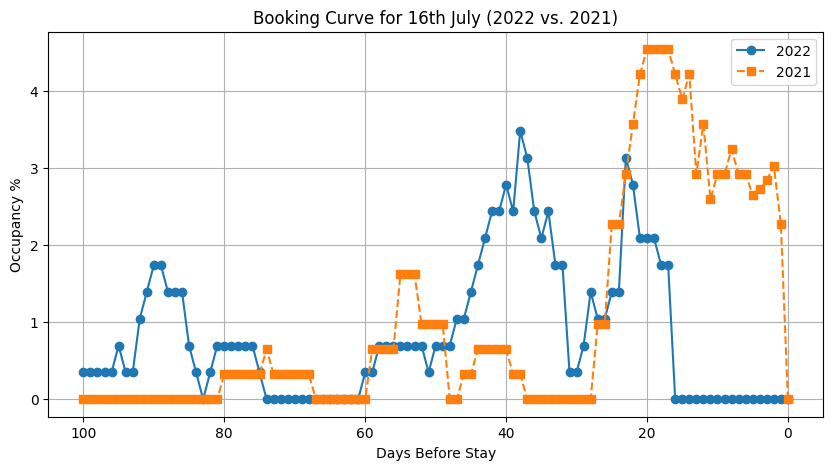

In [12]:
# Convert to DataFrame
df_curve = pd.DataFrame({
    "Days Before Stay": range(101),
    "2022 Occupancy %": curve_2022.values,
    "2021 Occupancy %": curve_2021.values
})

# Apply smoothing (rolling average)
df_curve["2022 Occupancy %"] = df_curve["2022 Occupancy %"].rolling(7, min_periods=1).mean()
df_curve["2021 Occupancy %"] = df_curve["2021 Occupancy %"].rolling(7, min_periods=1).mean()

# Plot the booking curves
plt.figure(figsize=(10, 5))
plt.plot(df_curve["Days Before Stay"], df_curve["2022 Occupancy %"], label="2022", marker="o", linestyle="-")
plt.plot(df_curve["Days Before Stay"], df_curve["2021 Occupancy %"], label="2021", marker="s", linestyle="--")
plt.xlabel("Days Before Stay")
plt.ylabel("Occupancy %")
plt.title("Booking Curve for 16th July (2022 vs. 2021)")
plt.legend()
plt.grid(True)
plt.gca().invert_xaxis()
# Save the figure
plt.savefig("booking_curve.png", dpi=300, bbox_inches="tight")
plt.show()